In [9]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score
from xgboost import XGBClassifier
import joblib
import os

In [10]:
df = pd.read_csv("credigo_credit_default_dataset.csv")


In [11]:
df

,customer_age,gender,marital_status,education,employment_type,monthly_income,employment_tenure_months,total_account_balance,total_debt,credit_score,...,loan_amount,loan_term_months,loan_purpose,loan_type,previous_loan_count,late_payment_count,max_days_past_due,previous_default_count,repayment_ratio,default_flag
0,55,Male,Single,Diploma,Part-time,20200.0,159,21200.0,154000.0,445,...,363000.0,36,Personal,Personal Loan,5,7,30,0,74.50,1
1,53,Male,Married,Bachelor,Full-time,52200.0,305,127000.0,378000.0,543,...,277000.0,48,Medical,Personal Loan,6,1,1,0,96.85,0
2,30,Other,Single,Bachelor,Self-employed,46800.0,25,41500.0,108000.0,681,...,518000.0,6,Personal,Personal Loan,2,1,15,0,94.75,0
3,54,Male,Divorced,Bachelor,Freelance,17700.0,28,21900.0,28000.0,599,...,99000.0,36,Education,Education Loan,4,2,7,0,92.95,0
4,37,Male,Single,High School,Full-time,18600.0,22,26600.0,145000.0,500,...,146000.0,24,Business,Business Loan,0,0,0,0,100.00,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,20,Male,Single,Bachelor,Part-time,34300.0,8,67400.0,119000.0,759,...,544000.0,24,Personal,Personal Loan,0,0,0,0,100.00,0
9996,28,Female,Married,Diploma,Freelance,14300.0,53,16500.0,30000.0,638,...,637000.0,36,Vehicle,Auto Loan,1,6,15,0,79.75,0
9997,45,Female,Divorced,Diploma,Freelance,29900.0,24,37000.0,124000.0,770,...,581000.0,36,Personal,Personal Loan,3,2,7,0,92.95,0
9998,40,Female,Married,High School,Full-time,25100.0,58,40600.0,124000.0,545,...,260000.0,36,Vehicle,Auto Loan,3,5,45,1,78.25,0


In [12]:
x = df.drop(columns=["default_flag"])
y = df["default_flag"]

In [13]:
categorical_feature = ["gender","marital_status","education","employment_type","loan_purpose","loan_type"] #ใช้ Onehotcoder แปลง
numerical_feature = [] # ใช้ StandardScaler() หน้าที่ของมันคือปรับ Scale ของตัวเลขให้มีค่าเฉลี่ยใกล้ 0 และส่วนเบี่ยงเบนมาตรฐานใกล้ 1
for col in x.columns :  
    if col not in categorical_feature : 
        numerical_feature.append(col)

In [14]:
preprocess = ColumnTransformer(transformers=[("num",StandardScaler(),numerical_feature),("cat",OneHotEncoder(),categorical_feature)])

# Pipeline 
model_lgs = Pipeline(steps=[("preprocess", preprocess),("classifier", LogisticRegression(max_iter=1000))])
model_rf = Pipeline(steps=[("preprocess", preprocess),("classifier", RandomForestClassifier( n_estimators=500,max_depth=15,min_samples_split=5,min_samples_leaf=2,max_features="sqrt",random_state=42,class_weight="balanced",n_jobs=-1,oob_score=True))])
model_xg = Pipeline(steps=[("preprocess",preprocess),("classifier",XGBClassifier(n_estimators=500,max_depth=2,learning_rate=0.01,subsample=1.0,colsample_bytree=0.8,min_child_weight=5,objective="binary:logistic",eval_metric="logloss",random_state=42,n_jobs=-1,reg_lambda=10))])
# Spilt 

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=0)

In [15]:
# Logistic Regression
model_lgs.fit(x_train,y_train)
y_pred_lgs = model_lgs.predict(x_test)
y_prob_lgs = model_lgs.predict(x_test)

# Randomforest
model_rf.fit(x_train,y_train)
y_pred_rf = model_rf.predict(x_test)
y_prob_rf = model_rf.predict(x_test)

# XGBOOST 
model_xg.fit(x_train,y_train)
y_pred_xg = model_xg.predict(x_test)
y_prob_xg =model_xg.predict(x_test)

In [16]:
# Evaluate Model Logistic 
print("Classification  Logistic Report:")
print(classification_report(y_test, y_pred_lgs))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgs))

print("ROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_lgs))

Classification  Logistic Report:
              precision    recall  f1-score   support

           0       0.85      0.98      0.91      1637
           1       0.70      0.21      0.33       363

    accuracy                           0.84      2000
   macro avg       0.77      0.60      0.62      2000
weighted avg       0.82      0.84      0.80      2000

Confusion Matrix:
[[1603   34]
 [ 285   78]]
ROC-AUC Score:
0.5970531661929451


In [17]:
# Evaluate Model Randomforest
print("Classification Randomforest Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("ROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_rf))

Classification Randomforest Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88      1637
           1       0.46      0.46      0.46       363

    accuracy                           0.80      2000
   macro avg       0.67      0.67      0.67      2000
weighted avg       0.80      0.80      0.80      2000

Confusion Matrix:
[[1438  199]
 [ 196  167]]
ROC-AUC Score:
0.6692456300664219


In [18]:
# Evaluate Model XGBOOST
print("Classification XG BOOST Report:")
print(classification_report(y_test, y_pred_xg))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xg))

print("ROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_xg))

Classification XG BOOST Report:
              precision    recall  f1-score   support

           0       0.84      0.98      0.90      1637
           1       0.64      0.16      0.25       363

    accuracy                           0.83      2000
   macro avg       0.74      0.57      0.58      2000
weighted avg       0.80      0.83      0.79      2000

Confusion Matrix:
[[1605   32]
 [ 306   57]]
ROC-AUC Score:
0.5687384199074097


In [26]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

# ---------- 1. ทำนาย probability ----------
y_prob_rf = model_rf.predict_proba(x_test)[:, 1]

# ---------- 2. วัด AUC ใหม่ ----------
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_prob_rf):.4f}")

# ---------- 3. ฟังก์ชัน Expected Profit ----------
def expected_profit(y_true, y_prob, t, profit_good=1.0, loss_bad=5.0):
    y_true = np.asarray(y_true).astype(int)
    y_pred = (y_prob >= t).astype(int)
    tp = ((y_true == 1) & (y_pred == 1)).sum()   # อนุมัติหนี้เสีย
    tn = ((y_true == 0) & (y_pred == 0)).sum()   # อนุมัติลูกค้าดี
    fn = ((y_true == 1) & (y_pred == 0)).sum()   # ปฏิเสธหนี้เสีย
    fp = ((y_true == 0) & (y_pred == 1)).sum()   # ปฏิเสธลูกค้าดี
    return tn * profit_good - tp * loss_bad, (tp, tn, fn, fp)

# ---------- 4. วน threshold ----------
print(f"\n{'t':>6} | {'TP':>4} {'TN':>5} {'FN':>4} {'FP':>4} | {'Profit':>8}")
print("-" * 50)
for t in [0.15, 0.20, 0.25, 0.30, 0.33, 0.40, 0.45, 0.48, 0.55, 0.60]:
    p, (tp, tn, fn, fp) = expected_profit(y_test, y_prob_rf, t)
    print(f"{t:>6.2f} | {tp:>4d} {tn:>5d} {fn:>4d} {fp:>4d} | {p:>+8.0f}")

ROC-AUC: 0.7613
PR-AUC:  0.4466

     t |   TP    TN   FN   FP |   Profit
--------------------------------------------------
  0.15 |  356   207    7 1430 |    -1573
  0.20 |  341   469   22 1168 |    -1236
  0.25 |  308   772   55  865 |     -768
  0.30 |  279   999   84  638 |     -396
  0.33 |  263  1092  100  545 |     -223
  0.40 |  222  1254  141  383 |     +144
  0.45 |  192  1350  171  287 |     +390
  0.48 |  176  1404  187  233 |     +524
  0.55 |  141  1495  222  142 |     +790
  0.60 |  112  1538  251   99 |     +978


Optimal threshold = 0.91, Max profit = +1637


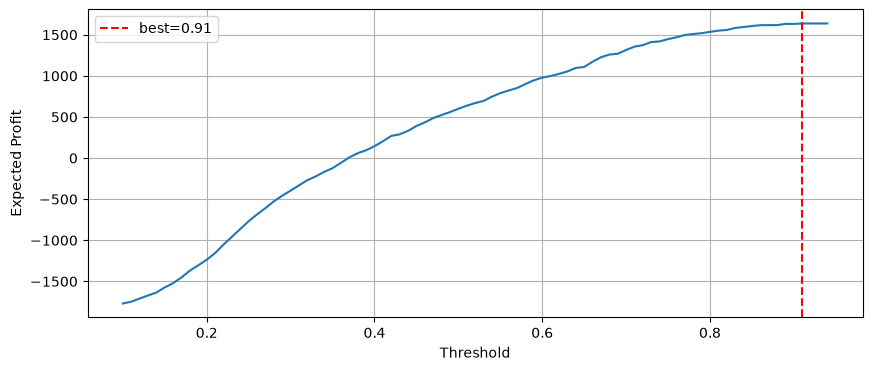

In [28]:
thresholds = np.arange(0.10, 0.95, 0.01)
profits = [expected_profit(y_test, y_prob_rf, t, loss_bad=5)[0] for t in thresholds]
best_t = thresholds[np.argmax(profits)]
print(f"Optimal threshold = {best_t:.2f}, Max profit = {max(profits):+.0f}")

# Plot ดู
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.plot(thresholds, profits)
plt.axvline(best_t, color='red', linestyle='--', label=f'best={best_t:.2f}')
plt.xlabel('Threshold'); plt.ylabel('Expected Profit')
plt.legend(); plt.grid(True); plt.show()

In [ ]:
# สมมติฐาน (ปรับตามธุรกิจจริง)
profit_per_good_loan = 1.0      # กำไรจากลูกค้าดี 1 ราย (หน่วย normalized)
loss_per_bad_loan = 5.0         # ขาดทุนจาก NPL 1 ราย

def expected_profit(y_true, y_prob, t):
    y_pred = (y_prob >= t).astype(int)
    tp = ((y_true == 1) & (y_pred == 1)).sum()   # อนุมัติหนี้เสีย (แย่)
    tn = ((y_true == 0) & (y_pred == 0)).sum()   # อนุมัติลูกค้าดี (ดี)
    fn = ((y_true == 1) & (y_pred == 0)).sum()   # ปฏิเสธหนี้เสีย (ดี)
    fp = ((y_true == 0) & (y_pred == 1)).sum()   # ปฏิเสธลูกค้าดี (แย่)
    return tn * profit_per_good_loan - tp * loss_per_bad_loan

for t in [0.20, 0.25, 0.30, 0.330, 0.40, 0.482, 0.55]:
    p = expected_profit(y_test, y_prob_rf, t)
    print(f"t={t:.3f} | Expected Profit = {p:+.0f}")


t=0.200 | Expected Profit = +603
t=0.250 | Expected Profit = +603
t=0.300 | Expected Profit = +603
t=0.330 | Expected Profit = +603
t=0.400 | Expected Profit = +603
t=0.482 | Expected Profit = +603
t=0.550 | Expected Profit = +603
ประเภท: <class 'numpy.ndarray'>
ค่าที่ไม่ซ้ำ (unique): [0 1]
จำนวนค่าที่ไม่ซ้ำ: 2
min/max: 0 1


In [ ]:
# Tunning Randomforest

'''
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score
param_grid = {
    "classifier__n_estimators": [100, 200, 300, 500],

    "classifier__max_depth": [5, 8, 12, 15, 20, None],

    "classifier__min_samples_split": [2, 5, 10, 15],

    "classifier__min_samples_leaf": [1, 2, 4, 8],

    "classifier__max_features": ["sqrt", "log2", 0.5],

    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

random_search = RandomizedSearchCV(
    estimator=model_rf,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Search for best parameters
random_search.fit(x_train, y_train)

# Get best model
best_rf_model = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation F1:")
print(random_search.best_score_)
''' 

'\nfrom sklearn.model_selection import RandomizedSearchCV\nfrom sklearn.metrics import make_scorer, f1_score\nparam_grid = {\n    "classifier__n_estimators": [100, 200, 300, 500],\n\n    "classifier__max_depth": [5, 8, 12, 15, 20, None],\n\n    "classifier__min_samples_split": [2, 5, 10, 15],\n\n    "classifier__min_samples_leaf": [1, 2, 4, 8],\n\n    "classifier__max_features": ["sqrt", "log2", 0.5],\n\n    "classifier__class_weight": [\n        "balanced",\n        "balanced_subsample"\n    ]\n}\n\nrandom_search = RandomizedSearchCV(\n    estimator=model_rf,\n    param_distributions=param_grid,\n    n_iter=30,\n    scoring="f1",\n    cv=5,\n    random_state=42,\n    n_jobs=-1,\n    verbose=1\n)\n\n# Search for best parameters\nrandom_search.fit(x_train, y_train)\n\n# Get best model\nbest_rf_model = random_search.best_estimator_\n\nprint("Best Parameters:")\nprint(random_search.best_params_)\n\nprint("\nBest Cross Validation F1:")\nprint(random_search.best_score_)\n'

In [ ]:
'''
param_grid_xgb = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__reg_lambda": [1, 3, 5, 10]
}

random_search_xgb = RandomizedSearchCV(
    estimator=model_xg,
    param_distributions=param_grid_xgb,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_xgb.fit(x_train, y_train)

best_xgb_model = random_search_xgb.best_estimator_

print("Best Parameters:")
print(random_search_xgb.best_params_)

print("Best CV F1:")
print(random_search_xgb.best_score_)

'''

'\nparam_grid_xgb = {\n    "classifier__n_estimators": [100, 200, 300, 500],\n    "classifier__max_depth": [2, 3, 4, 5, 6],\n    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],\n    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],\n    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],\n    "classifier__min_child_weight": [1, 3, 5, 7],\n    "classifier__reg_lambda": [1, 3, 5, 10]\n}\n\nrandom_search_xgb = RandomizedSearchCV(\n    estimator=model_xg,\n    param_distributions=param_grid_xgb,\n    n_iter=30,\n    scoring="f1",\n    cv=5,\n    random_state=42,\n    n_jobs=-1,\n    verbose=1\n)\n\nrandom_search_xgb.fit(x_train, y_train)\n\nbest_xgb_model = random_search_xgb.best_estimator_\n\nprint("Best Parameters:")\nprint(random_search_xgb.best_params_)\n\nprint("Best CV F1:")\nprint(random_search_xgb.best_score_)\n\n'

In [ ]:
#joblib.dump(model_rf,"random_forest_model.pkl")

['C:\\Users\\Ittikorn\\Music\\Credigo\\ml_training\\random_forest_model.pkl']

In [29]:
import joblib

MODEL_PATH = r"C:\Users\Ittikorn\Music\Credigo\ml_training\random_forest_model.pkl"

# Load Model
model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(model))

# Predict
predictions = model.predict(x_test)

# Predict Probability
probabilities = model.predict_proba(x_test)

print("Predictions:", predictions[:10])
print("Probabilities:", probabilities[:10])

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Predictions: [0 1 0 1 0 0 1 0 1 1]
Probabilities: [[0.71896841 0.28103159]
 [0.17623632 0.82376368]
 [0.77251003 0.22748997]
 [0.43690359 0.56309641]
 [0.84559382 0.15440618]
 [0.84876721 0.15123279]
 [0.46649293 0.53350707]
 [0.54486392 0.45513608]
 [0.45576598 0.54423402]
 [0.4053896  0.5946104 ]]
